# Retail Sales Performance Analysis
**Project ID:** DA-011 | **Domain:** Retail & Sales

This notebook analyzes store transaction data to understand sales trends over time, identify top-performing products and categories, and evaluate sales performance across different store locations.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean plot style
sns.set_theme(style="whitegrid")


## Loading the Dataset
We start by loading the transaction records from `data.csv`.


In [3]:
salesRecords = pd.read_csv('data.csv')
salesRecords.head()


,Transaction_ID,Date,Product_Name,Quantity,Unit_Price,Store_Location,Category
0,TX-10000,2025-01-01 00:00:00,Vitamin C Skincare Serum,3,45.00,Bangalore,Beauty & Health
1,TX-10001,2025-01-01 04:00:00,Smart Coffee Maker,2,89.99,Mumbai,Home & Kitchen
2,TX-10002,2025-01-01 08:00:00,Premium Running Shoes,2,NaN,Chennai,Apparel
3,TX-10003,2025-01-01 12:00:00,Vitamin C Skincare Serum,3,45.00,Bangalore,Beauty & Health
4,TX-10004,2025-01-01 16:00:00,Ergonomic Desk Chair,3,249.99,Delhi,Home & Kitchen


## Data Cleaning and Preparation
We check for missing values, duplicate entries, and format the data types properly.


In [4]:
# Check dataset shape and missing values
print("Total rows and columns:", salesRecords.shape)
print("\nMissing values per column:")
print(salesRecords.isnull().sum())
print("\nDuplicate records found:", salesRecords.duplicated().sum())


Total rows and columns: (1545, 7)

Missing values per column:
Transaction_ID     0
Date               0
Product_Name       0
Quantity           0
Unit_Price        78
Store_Location     0
Category           0
dtype: int64

Duplicate records found: 45


We remove duplicate rows, fill missing unit prices using the known product price, and convert the transaction date into datetime.


In [5]:
# Remove duplicate entries
salesRecords = salesRecords.drop_duplicates()

# Fill missing unit prices using the median price for each product
salesRecords['Unit_Price'] = salesRecords.groupby('Product_Name')['Unit_Price'].transform(
    lambda priceGroup: priceGroup.fillna(priceGroup.median())
)

# Convert Date to datetime format
salesRecords['Date'] = pd.to_datetime(salesRecords['Date'])

# Create total sales and month columns
salesRecords['Total_Sales'] = salesRecords['Quantity'] * salesRecords['Unit_Price']
salesRecords['Transaction_Month'] = salesRecords['Date'].dt.strftime('%Y-%m')

print("Cleaning complete. Updated shape:", salesRecords.shape)
salesRecords.head()


Cleaning complete. Updated shape: (1500, 9)


,Transaction_ID,Date,Product_Name,Quantity,Unit_Price,Store_Location,Category,Total_Sales,Transaction_Month
0,TX-10000,2025-01-01 00:00:00,Vitamin C Skincare Serum,3,45.00,Bangalore,Beauty & Health,135.00,2025-01
1,TX-10001,2025-01-01 04:00:00,Smart Coffee Maker,2,89.99,Mumbai,Home & Kitchen,179.98,2025-01
2,TX-10002,2025-01-01 08:00:00,Premium Running Shoes,2,120.00,Chennai,Apparel,240.00,2025-01
3,TX-10003,2025-01-01 12:00:00,Vitamin C Skincare Serum,3,45.00,Bangalore,Beauty & Health,135.00,2025-01
4,TX-10004,2025-01-01 16:00:00,Ergonomic Desk Chair,3,249.99,Delhi,Home & Kitchen,749.97,2025-01


## Overall Sales Overview
Here are the overall key numbers across all store transactions.


In [6]:
totalStoreRevenue = salesRecords['Total_Sales'].sum()
totalCompletedOrders = salesRecords['Transaction_ID'].nunique()
totalItemsSold = salesRecords['Quantity'].sum()
averageOrderSpend = salesRecords['Total_Sales'].mean()

print("--- Overall Store Summary ---")
print(f"Total Revenue       : ₹{totalStoreRevenue:,.2f}")
print(f"Total Orders        : {totalCompletedOrders:,}")
print(f"Total Items Sold    : {totalItemsSold:,}")
print(f"Average Order Spend : ₹{averageOrderSpend:,.2f}")


--- Overall Store Summary ---
Total Revenue       : ₹1,101,336.28
Total Orders        : 1,500
Total Items Sold    : 3,682
Average Order Spend : ₹734.22


## Monthly Sales Trend
We track total revenue across months to see how sales perform over time.


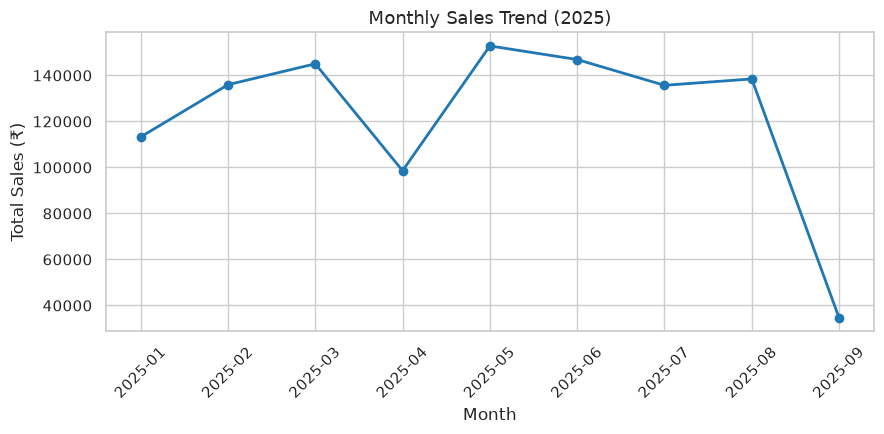

In [7]:
monthlyRevenueTrend = salesRecords.groupby('Transaction_Month')['Total_Sales'].sum().reset_index()

# Plot monthly sales trend
plt.figure(figsize=(9, 4.5))
plt.plot(monthlyRevenueTrend['Transaction_Month'], monthlyRevenueTrend['Total_Sales'], marker='o', color='#1f77b4', linewidth=2)
plt.title('Monthly Sales Trend (2025)', fontsize=13)
plt.xlabel('Month')
plt.ylabel('Total Sales (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Product Sales Performance
We group transactions by product to find our highest earning items.


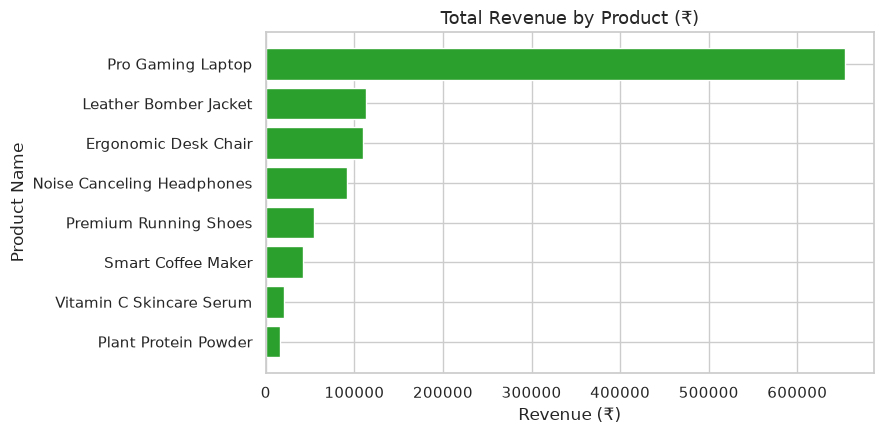

In [8]:
productRevenueSummary = salesRecords.groupby('Product_Name').agg(
    totalRevenue=('Total_Sales', 'sum'),
    unitsSold=('Quantity', 'sum')
).sort_values(by='totalRevenue', ascending=True).reset_index()

# Bar chart of revenue by product
plt.figure(figsize=(9, 4.5))
plt.barh(productRevenueSummary['Product_Name'], productRevenueSummary['totalRevenue'], color='#2ca02c')
plt.title('Total Revenue by Product (₹)', fontsize=13)
plt.xlabel('Revenue (₹)')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()


## Sales by Product Category
Here we compare revenue across the four main categories: Electronics, Apparel, Home & Kitchen, and Beauty & Health.


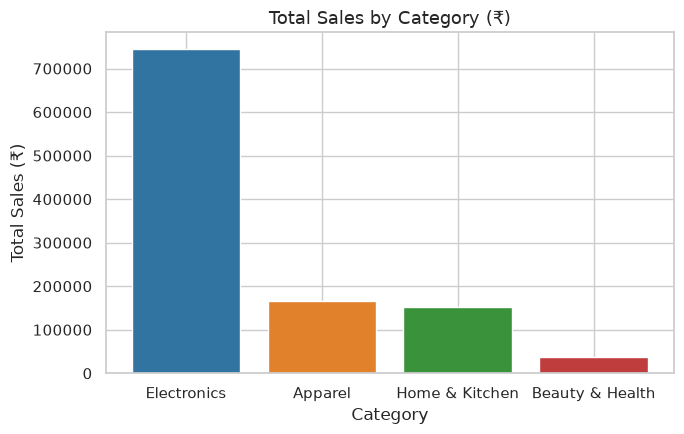

In [9]:
categoryRevenueSummary = salesRecords.groupby('Category')['Total_Sales'].sum().sort_values(ascending=False).reset_index()

# Bar chart of sales by category
plt.figure(figsize=(7, 4.5))
plt.bar(categoryRevenueSummary['Category'], categoryRevenueSummary['Total_Sales'], color=['#3274a1', '#e1812c', '#3a923a', '#c03d3e'])
plt.title('Total Sales by Category (₹)', fontsize=13)
plt.xlabel('Category')
plt.ylabel('Total Sales (₹)')
plt.tight_layout()
plt.show()


## Sales by Store Location
We compare store sales across different cities to see which branches perform best.


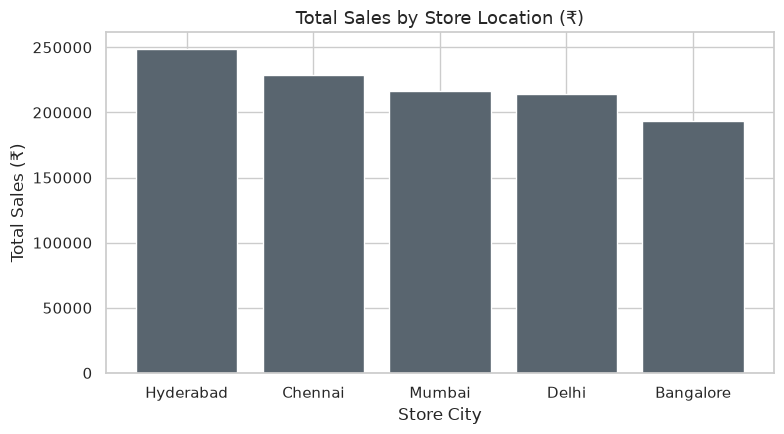

In [10]:
locationRevenueSummary = salesRecords.groupby('Store_Location')['Total_Sales'].sum().sort_values(ascending=False).reset_index()

# Bar chart of sales by location
plt.figure(figsize=(8, 4.5))
plt.bar(locationRevenueSummary['Store_Location'], locationRevenueSummary['Total_Sales'], color='#59656f')
plt.title('Total Sales by Store Location (₹)', fontsize=13)
plt.xlabel('Store City')
plt.ylabel('Total Sales (₹)')
plt.tight_layout()
plt.show()


## Summary

### Key Findings:
- **Sales Trends:** Sales peaked in May (₹152,812) and June (₹146,898), with consistent monthly earnings above ₹110,000 across the first two quarters.
- **Top Products:** The **Pro Gaming Laptop** generates the highest revenue (over ₹650,000), accounting for the majority of store sales.
- **Top Categories:** **Electronics** is the leading category by far, followed by Apparel, Home & Kitchen, and Beauty & Health.
- **Top Locations:** **Hyderabad** and **Chennai** are the top-earning store branches, while Bangalore has the lowest sales.

